# Phase D — Cross-Phase Analysis and Exploratory Data Analysis

Combines every output so far (Phase A liveness, Phase B TLS/PQ + HTTP, Phase C1-C4 derived
measurements) into one per-domain table, then asks the cross-phase questions no single phase
script answers on its own:

1. Does certificate strength correlate with post-quantum adoption?
2. Do SSLv3/3DES-accepting domains cluster on the same hosts as weak-certificate domains?
3. Is DNSSEC adoption related to TLS posture, or independent of it?
4. **SMTP/STARTTLS on its own, full population** -- the main join is scoped to Phase B's live
   (HTTPS) domains, which does NOT include every domain c4 covers (some have mail but no
   website). A dedicated section below uses c4's real, complete population.
5. **Operator-level grouping** (flagged as not-yet-done in `PLAN.md`'s open items): do several
   IPs belonging to one real operator, currently counted as separate "servers", change the
   picture once grouped?
6. A full sector x tier breakdown across every metric at once.

**Data sources** (all read-only; nothing here re-runs a scan):
`phase_b_domains.csv`, `phase_c1_keys.csv`, `phase_c2_ciphers.csv`, `phase_c3_domains.csv`,
`phase_c4_domains.csv` — all in `data/measurement/processed/`.

**Two things to keep in mind throughout, carried over from every earlier phase:**
- Domains sharing a server are not independent measurements. Every statistic below is shown
  per domain AND per server where that distinction matters; where they diverge, the per-server
  number is the one to trust.
- A percentage computed from a small number of domains is noise, not a finding. Every summary
  table in this notebook shows the real count behind each percentage, and switches to a plain
  "k/n" display (no percentage at all) below `MIN_N = 30` observations.

In [20]:
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

PROC = Path("data/measurement/processed")
FIG = Path("results/figures")
FIG.mkdir(parents=True, exist_ok=True)

MIN_N = 30  # a percentage below this many observations is shown as a raw count instead


def savefig(fig, name):
    """Save at publication quality alongside displaying it inline."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=200)
    print(f"saved: results/figures/{name}.png")


def small_n_cell(n_true, n, pct, min_n=MIN_N):
    """Format one table cell: a clean percentage if there's enough data behind it, otherwise
    the raw count so nobody mistakes noise for a finding. Used by every summary table below."""
    if n == 0:
        return "–"
    if n < min_n:
        return f"{n_true}/{n} (n<{min_n})"
    return f"{pct}%"

## 1. Load and join every data source

Each file is loaded independently (so a missing Phase C file degrades gracefully rather than
crashing the whole notebook) and left-joined onto Phase B's domain list, since that's the live,
7,999-domain population every later phase measured against. **Note:** this means a domain c4
covers but that has no live website will NOT appear in `df` -- see Section 4 for why that matters
and how it's handled separately.

In [21]:
def load_csv(name, required=True):
    path = PROC / name
    if not path.exists():
        if required:
            raise FileNotFoundError(f"{path} not found -- run the corresponding phase script first.")
        print(f"(optional) {name} not found -- skipping that join.")
        return None
    df = pd.read_csv(path)
    print(f"{name}: {len(df):,} rows, {df['domain'].nunique():,} unique domains" if "domain" in df else f"{name}: {len(df):,} rows")
    return df


b3 = load_csv("phase_b_domains.csv")
c1 = load_csv("phase_c1_keys.csv", required=False)
c2 = load_csv("phase_c2_ciphers.csv", required=False)
c3 = load_csv("phase_c3_domains.csv", required=False)
c4 = load_csv("phase_c4_domains.csv", required=False)   # kept as its own frame too -- see Section 4

phase_b_domains.csv: 7,999 rows, 7,999 unique domains
phase_c1_keys.csv: 7,999 rows, 7,999 unique domains
phase_c2_ciphers.csv: 7,999 rows, 7,999 unique domains
phase_c3_domains.csv: 9,028 rows, 9,028 unique domains
phase_c4_domains.csv: 2,633 rows, 2,633 unique domains


In [22]:
# Suffix every non-key column from c1/c2/c3/c4 so a join never silently overwrites a same-named
# b3 column (both b3 and c1 have "ip", for example -- keep b3's as the one true IP column).
# "status" is deliberately NOT in this shared drop list -- only c4 has a bare "status" column
# (its SMTP probe result), and it does not collide with b3's "tls_status"/"http_status". Dropping
# it for every source (an earlier version of this notebook did) silently discarded c4's data.
KEEP_KEYS = {"domain"}


def prefixed(df, prefix, drop=("category", "tier", "ip", "is_service_hostname", "live")):
    if df is None:
        return None
    d = df.drop(columns=[c for c in drop if c in df.columns])
    return d.rename(columns={c: f"{prefix}_{c}" for c in d.columns if c not in KEEP_KEYS})


df = b3.copy()
for frame, prefix in ((c1, "c1"), (c2, "c2"), (c3, "c3"), (c4, "c4")):
    part = prefixed(frame, prefix)
    if part is not None:
        df = df.merge(part, on="domain", how="left")

print(f"\nJoined table: {len(df):,} domains, {df.shape[1]} columns")
print(f"Distinct servers (unique IPs): {df['ip'].nunique():,}")
df.head(3)


Joined table: 7,999 domains, 69 columns
Distinct servers (unique IPs): 1,861


,domain,category,tier,ip,domains_on_ip,is_service_hostname,tls_status,tls_version,cipher,group,pq_class,pq_intolerant,legacy_only,accepts_tls_1_0_or_1_1,cert_trusted,cert_expired,cert_self_signed,cert_hostname_match,cert_key_type,cert_key_bits,cert_sig_hash,cert_issuer_o,cert_serial_non_positive,http_status,http_source,http_status_code,hsts_present,hsts_max_age,hsts_include_subdomains,hsts_preload,...,c1_leaf_status,c1_chain_weakest_strength,c1_chain_status,c1_weak_sig_hash,c1_pq_signature,c1_quantum_vulnerable,c2_primary_cipher,c2_primary_tls_version,c2_old_version_cipher,c2_old_version_tls_version,c2_lucky13_beast_exposed,c2_idea_negotiated,c2_accepts_sslv3,c2_poodle_exposed,c2_sslv3_cipher,c2_accepts_3des,c2_des3_protocol,c2_des3_cipher,c2_poodle_tested,c2_des3_probed,c3_registered_domain,c3_is_apex,c3_ad_validated,c3_ds_present,c3_dnskey_present,c4_mx_host,c4_status,c4_starttls_offered,c4_tls_version,c4_cipher
0,12foundation.daffodilvarsity.edu.bd,university,verified,203.190.10.99,78,False,ok,TLSv1.3,TLS_AES_256_GCM_SHA384,x25519,not_capable,False,False,False,True,False,False,True,RSA,2048.0,sha256,Let's Encrypt,NaN,ok,primary,200.0,False,NaN,NaN,NaN,...,only_112,112.0,only_112,False,NaN,True,TLS_AES_256_GCM_SHA384,TLSv1.3,NaN,NaN,NaN,False,False,False,NaN,False,NaN,NaN,True,True,daffodilvarsity.edu.bd,False,False,False,False,NaN,NaN,NaN,NaN,NaN
1,333.gov.bd,government,unverified,104.21.15.9,1,False,ok,TLSv1.3,TLS_AES_256_GCM_SHA384,X25519MLKEM768,pq_default,False,False,True,True,False,False,True,EC,256.0,sha256,Google Trust Services,NaN,ok,primary,200.0,True,63072000.0,True,True,...,128_plus,128.0,128_plus,False,NaN,True,TLS_AES_256_GCM_SHA384,TLSv1.3,ECDHE-ECDSA-AES128-SHA,TLSv1.1,True,False,False,False,NaN,False,NaN,NaN,True,True,333.gov.bd,True,False,False,False,mail.333.gov.bd,connect_timeout,NaN,NaN,NaN
2,365tickets.com.bd,commercial,unverified,104.21.59.205,1,False,ok,TLSv1.3,TLS_AES_256_GCM_SHA384,X25519MLKEM768,pq_default,False,False,True,True,False,False,True,EC,256.0,sha256,Google Trust Services,NaN,ok,primary,530.0,False,NaN,NaN,NaN,...,128_plus,128.0,128_plus,False,NaN,True,TLS_AES_256_GCM_SHA384,TLSv1.3,ECDHE-ECDSA-AES128-SHA,TLSv1.1,True,False,False,False,NaN,False,NaN,NaN,True,True,365tickets.com.bd,True,False,False,False,aspmx.l.google.com,ok,True,TLSv1.3,TLS_AES_256_GCM_SHA384


### Coverage check

Before drawing any conclusion, confirm how much of the 7,999-domain live set actually has data
from each later phase — Phase C steps were scoped differently (c1/c2 cover certificates that
exist; c3's DNSSEC AD flag comes from Phase A regardless of HTTPS; c4 is scoped from MX records,
not HTTPS liveness at all, so the number below is deliberately NOT c4's full population — see
Section 4).

In [23]:
coverage = pd.DataFrame({
    "has_b3_cert": df["cert_trusted"].notna() if "cert_trusted" in df else pd.Series(dtype=bool),
    "has_c1": df["c1_has_cert"].notna() if "c1_has_cert" in df else pd.Series(dtype=bool),
    "has_c2_legacy": df["c2_accepts_sslv3"].notna() if "c2_accepts_sslv3" in df else pd.Series(dtype=bool),
    "has_c3_dnssec": df["c3_ad_validated"].notna() if "c3_ad_validated" in df else pd.Series(dtype=bool),
    "has_c4_smtp_AMONG_LIVE_DOMAINS": df["c4_status"].notna() if "c4_status" in df else pd.Series(dtype=bool),
}).sum().rename("domains_with_data")
coverage.to_frame()

,domains_with_data
has_b3_cert,7827
has_c1,7999
has_c2_legacy,7962
has_c3_dnssec,7999
has_c4_smtp_AMONG_LIVE_DOMAINS,2457


## 2. Does certificate strength correlate with post-quantum adoption?

A server operator who upgraded to a modern, post-quantum-capable TLS stack might also be more
likely to run a current, well-configured certificate — or the two could be entirely unrelated
(a PQ-capable library ships with any OpenSSL build; it says nothing about certificate hygiene).
This is testable directly.

In [24]:
is_pq = df["pq_class"] == "pq_default"
has_cert = df["cert_trusted"].notna()
sub = df.loc[has_cert, ["pq_class", "cert_trusted", "cert_key_type", "ip"]].copy()
sub["pq_default"] = sub["pq_class"] == "pq_default"

cert_by_pq = sub.groupby("pq_default")["cert_trusted"].agg(["mean", "count"]).rename(
    columns={"mean": "pct_cert_trusted", "count": "domains"})
cert_by_pq["pct_cert_trusted"] = (cert_by_pq["pct_cert_trusted"] * 100).round(1)
cert_by_pq

,pct_cert_trusted,domains
pq_default,,
False,55.0,3943
True,96.3,3884


In [25]:
# Same question, but weighted by SERVER (each IP counted once) -- the number to actually trust,
# per this project's standing rule that shared hosting makes domains non-independent.
srv = sub.groupby("ip").agg(pq_default=("pq_default", "any"), cert_trusted=("cert_trusted", "mean")).reset_index()
srv["cert_trusted_majority"] = srv["cert_trusted"] >= 0.5
cert_by_pq_srv = srv.groupby("pq_default")["cert_trusted_majority"].agg(["mean", "count"]).rename(
    columns={"mean": "pct_servers_mostly_trusted", "count": "servers"})
cert_by_pq_srv["pct_servers_mostly_trusted"] = (cert_by_pq_srv["pct_servers_mostly_trusted"] * 100).round(1)
cert_by_pq_srv

,pct_servers_mostly_trusted,servers
pq_default,,
False,80.8,875
True,97.9,959


saved: results/figures/d_pq_vs_cert_trust.png


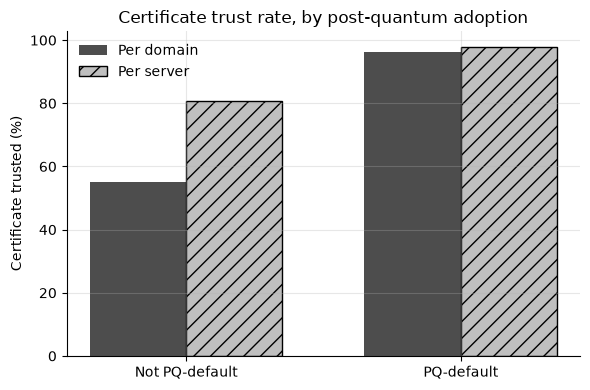

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2)
w = 0.35
dom_vals = cert_by_pq["pct_cert_trusted"].reindex([False, True]).values
srv_vals = cert_by_pq_srv["pct_servers_mostly_trusted"].reindex([False, True]).values
ax.bar(x - w/2, dom_vals, w, label="Per domain", color="#4d4d4d")
ax.bar(x + w/2, srv_vals, w, label="Per server", color="#bfbfbf", hatch="//", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["Not PQ-default", "PQ-default"])
ax.set_ylabel("Certificate trusted (%)")
ax.set_title("Certificate trust rate, by post-quantum adoption")
ax.legend(frameon=False)
plt.tight_layout()
savefig(fig, "d_pq_vs_cert_trust")
plt.show()

**Read this result with the same caution as every correlation in this project:** a shared
host's PQ status and certificate status are set by the SAME operator decision, not by 7,999
independent choices. A strong-looking correlation here could be two or three large operators'
configuration choices, not a general pattern. The per-server view above is the real test; if it's
much weaker than the per-domain one, that confirms the correlation is mostly a hosting-platform
artifact, the same conclusion Section 5.5 already reached for the sector gap.

## 3. Do SSLv3/3DES-accepting hosts also have weak certificates?

If a server is still running an unpatched or ancient TLS stack (SSLv3, 3DES), does it also tend
to have a weak or broken certificate? These are set independently in principle (certificate
rotation and protocol support are different operational tasks) but could still correlate if both
trace back to one underlying cause: an unmaintained server.

In [27]:
if "c2_accepts_sslv3" in df.columns:
    legacy = df.dropna(subset=["c2_accepts_sslv3", "cert_trusted"]).copy()
    legacy["legacy_exposed"] = (legacy["c2_accepts_sslv3"].astype(bool) |
                                legacy.get("c2_accepts_3des", pd.Series(False, index=legacy.index)).fillna(False).astype(bool))
    tab = legacy.groupby("legacy_exposed")["cert_trusted"].agg(["mean", "count"]).rename(
        columns={"mean": "pct_cert_trusted", "count": "domains"})
    tab["pct_cert_trusted"] = (tab["pct_cert_trusted"] * 100).round(1)
    display(tab)

    srv2 = legacy.groupby("ip").agg(legacy_exposed=("legacy_exposed", "any"),
                                    cert_trusted=("cert_trusted", "mean")).reset_index()
    print(f"\n{srv2['legacy_exposed'].sum()} of {len(srv2)} servers show SSLv3 and/or 3DES acceptance "
          f"on at least one probed domain.")
else:
    print("c2 (legacy cipher) data not joined -- run c2_legacy_cipher_inference.py and re-load.")

,pct_cert_trusted,domains
legacy_exposed,,
False,75.6,7625
True,69.3,179



102 of 1817 servers show SSLv3 and/or 3DES acceptance on at least one probed domain.


## 4. Is DNSSEC adoption related to TLS/PQ posture?

DNSSEC (signing the DNS zone) and TLS configuration (securing the connection once you've reached
the server) are unrelated protocols, run by potentially different teams within the same
institution. A real finding here either way — correlated or independent — is worth stating
plainly rather than assumed.

In [28]:
if "c3_ad_validated" in df.columns:
    dnssec = df.dropna(subset=["c3_ad_validated"]).copy()
    tab2 = dnssec.groupby("c3_ad_validated")["pq_class"].value_counts(normalize=True).unstack().fillna(0) * 100
    display(tab2.round(1))
    n_validated = int(dnssec["c3_ad_validated"].astype(bool).sum())
    print(f"\n{n_validated} of {len(dnssec)} domains in this table have DNSSEC-validated DNS "
          f"({'too few to draw a real conclusion -- treat this section as illustrative only' if n_validated < MIN_N else 'a usable sample size'}).")
else:
    print("c3 (DNSSEC) data not joined -- run c3_dnssec_summary.py and re-load.")

pq_class,no_tls13,not_capable,pq_capable_not_default,pq_default,unknown
c3_ad_validated,,,,,
False,5.0,43.2,0.0,48.8,2.9
True,12.8,58.1,0.0,24.4,4.7



86 of 7999 domains in this table have DNSSEC-validated DNS (a usable sample size).


## 5. SMTP/STARTTLS on its full, real population (not just the live-domain join)

**Why this section exists on its own:** `df` above is built on Phase B's 7,999-domain *live
(HTTPS)* set. c4 was deliberately scoped differently — it covers every domain with a usable MX
record, including domains that run mail but have no website at all (Phase A found 816 such
domains; a number of them have MX records). Those domains are simply absent from `df`, so any
STARTTLS statistic computed through the join above silently undercounts c4's real population.
This section reads `c4` directly, on its own terms, so the numbers here match c4's own report
exactly.

In [29]:
if c4 is not None:
    web_live_domains = set(df["domain"])
    c4_domains = set(c4["domain"])
    mail_only = c4_domains - web_live_domains
    print(f"c4's real population: {len(c4_domains):,} domains with a usable MX record")
    print(f"  of which {len(c4_domains & web_live_domains):,} also have a live website (covered by the join above)")
    print(f"  of which {len(mail_only):,} have NO live website (mail-only -- invisible to Section 1's `df`)")
    if mail_only:
        print(f"  example mail-only domains: {sorted(mail_only)[:5]}")
else:
    print("c4 not loaded -- run c4_smtp_scan.py and re-load.")

c4's real population: 2,633 domains with a usable MX record
  of which 2,457 also have a live website (covered by the join above)
  of which 176 have NO live website (mail-only -- invisible to Section 1's `df`)
  example mail-only domains: ['adjunct.eastdelta.edu.bd', 'adminbeta.uiu.ac.bd', 'admission.nubtkhulna.ac.bd', 'ahs.ku.ac.bd', 'ais.du.ac.bd']


In [30]:
if c4 is not None:
    def starttls_stats(frame):
        s = frame["starttls_offered"].dropna()
        n, n_true = len(s), int(s.astype(bool).sum())
        pct = round(100 * n_true / n, 1) if n else np.nan
        return pd.Series({"domains": len(frame), "mx_hosts": frame["mx_host"].nunique(),
                          "starttls_n": n_true, "starttls_den": n, "starttls_pct": pct})

    c4_by_cat = c4.groupby("category").apply(starttls_stats).reset_index()
    for col in ("domains", "mx_hosts", "starttls_n", "starttls_den"):
        c4_by_cat[col] = c4_by_cat[col].astype(int)
    c4_by_cat["starttls_display"] = [small_n_cell(r.starttls_n, r.starttls_den, r.starttls_pct)
                                     for r in c4_by_cat.itertuples()]
    c4_by_cat = c4_by_cat.sort_values("domains", ascending=False)
    print("This table (from c4 directly) is the one to cite for SMTP/STARTTLS by sector --")
    print("not any c4_* column reached through the join in Section 1.\n")
    display(c4_by_cat[["category", "domains", "mx_hosts", "starttls_n", "starttls_den", "starttls_display"]])
else:
    print("c4 not loaded.")

This table (from c4 directly) is the one to cite for SMTP/STARTTLS by sector --
not any c4_* column reached through the join in Section 1.



,category,domains,mx_hosts,starttls_n,starttls_den,starttls_display
6,university,1443,369,1190,1190,100.0%
1,commercial,568,321,488,490,99.6%
3,government,501,131,225,225,100.0%
5,unclassified,90,61,70,71,98.6%
0,banking,25,18,20,20,20/20 (n<30)
2,defence,4,3,2,3,2/3 (n<30)
4,telecom,2,2,2,2,2/2 (n<30)


## 6. Operator-level grouping

`PLAN.md`'s open items flag this directly: several IPs can belong to one real hosting operator
(the six-IP government platform found in Phase B, for example), and counting them as six separate
"servers" understates how concentrated the real infrastructure landscape is.

**No authoritative IP-to-operator database is available offline**, so this section uses two
approximate, clearly-labeled proxies rather than claiming a ground-truth mapping:

1. **Same /24 subnet** — IPs that differ only in their last octet very often belong to one
   organisation's address block. This is a heuristic, not a WHOIS lookup: a cloud provider's
   shared address pool would falsely group unrelated customers this way, and conversely one real
   operator can easily hold IPs in several unrelated /24 blocks that this method will never link.
2. **Known provider name match** — certificate issuer, WAF/CDN vendor (from Phase B), or hostname
   pattern naming a known operator (Google, Cloudflare, Amazon, Microsoft/Outlook, cPanel-style
   hosting panels already flagged via `is_service_hostname`).

Both are reported with their real sample sizes; neither should be cited alone as a precise
operator count, and a provider row below `MIN_N` domains is flagged exactly as in every other
table in this notebook.

In [31]:
def subnet24(ip):
    parts = str(ip).split(".")
    return ".".join(parts[:3]) + ".0/24" if len(parts) == 4 else ip


df["subnet24"] = df["ip"].map(subnet24)

by_subnet = (df.groupby("subnet24").agg(domains=("domain", "count"), ips_in_subnet=("ip", "nunique"),
                                        pct_pq_default=("pq_class", lambda s: round(100 * (s == "pq_default").mean(), 1)))
            .query("ips_in_subnet > 1 or domains >= 10")
            .sort_values("domains", ascending=False))
print(f"{len(by_subnet)} /24 subnets host more than one of this sample's IPs or >=10 domains "
      f"(out of {df['subnet24'].nunique()} distinct subnets total).")
by_subnet.head(15)

356 /24 subnets host more than one of this sample's IPs or >=10 domains (out of 968 distinct subnets total).


,domains,ips_in_subnet,pct_pq_default
subnet24,,,
103.157.135.0/24,1323,24,92.1
159.13.21.0/24,889,5,0.0
103.159.2.0/24,293,34,47.8
203.96.189.0/24,203,24,69.0
131.186.50.0/24,167,3,0.0
103.108.140.0/24,146,4,95.9
159.13.20.0/24,130,6,0.0
131.186.51.0/24,106,4,0.0
203.190.10.0/24,102,2,0.0


In [32]:
PROVIDER_PATTERNS = {
    "Google": r"google|gmail|aspmx",
    "Cloudflare": r"cloudflare",
    "Amazon/AWS": r"amazon|aws|cloudfront",
    "Microsoft/Outlook": r"outlook|microsoft|office365",
    "cPanel-style shared hosting": r"^cpanel|^webmail|^webdisk|^whm",
}


def match_provider(row):
    text = " ".join(str(row.get(c, "")) for c in ("domain", "cert_issuer_o", "waf_vendors") if c in row.index).lower()
    for name, pattern in PROVIDER_PATTERNS.items():
        if re.search(pattern, text):
            return name
    return None


df["provider_guess"] = df.apply(match_provider, axis=1)


def provider_stats(frame):
    n, n_true = len(frame), int((frame["pq_class"] == "pq_default").sum())
    pct = round(100 * n_true / n, 1) if n else np.nan
    return pd.Series({"domains": n, "servers": frame["ip"].nunique(), "pq_n": n_true,
                      "pq_den": n, "pq_pct": pct})


provider_summary = df.dropna(subset=["provider_guess"]).groupby("provider_guess").apply(provider_stats)
for col in ("domains", "servers", "pq_n", "pq_den"):
    provider_summary[col] = provider_summary[col].astype(int)
provider_summary["pq_display"] = [small_n_cell(r.pq_n, r.pq_den, r.pq_pct) for r in provider_summary.itertuples()]
provider_summary = provider_summary.sort_values("domains", ascending=False)
provider_summary[["domains", "servers", "pq_n", "pq_den", "pq_display"]]

,domains,servers,pq_n,pq_den,pq_display
provider_guess,,,,,
Google,1060,510,1050,1060,99.1%
cPanel-style shared hosting,423,92,251,423,59.3%
Cloudflare,107,60,106,107,99.1%
Amazon/AWS,21,17,12,21,12/21 (n<30)
Microsoft/Outlook,7,4,0,7,0/7 (n<30)


saved: results/figures/d_provider_groups.png


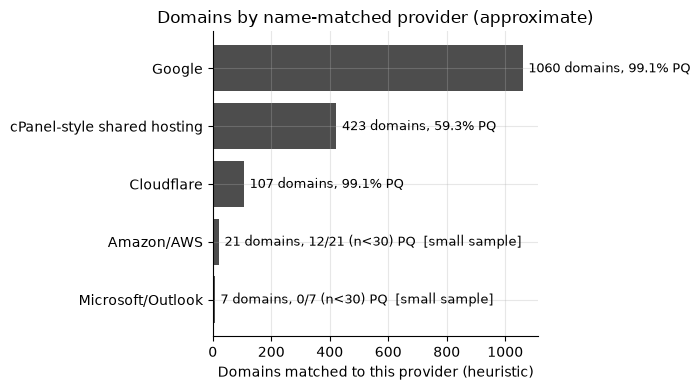

In [33]:
fig, ax = plt.subplots(figsize=(7, 4))
top = provider_summary.sort_values("domains", ascending=True)
ax.barh(top.index, top["domains"], color="#4d4d4d")
for i, (n, label, den) in enumerate(zip(top["domains"], top["pq_display"], top["pq_den"])):
    flag = "  [small sample]" if den < MIN_N else ""
    ax.annotate(f"{n} domains, {label} PQ{flag}", (n, i), xytext=(4, 0), textcoords="offset points",
               va="center", fontsize=9)
ax.set_xlabel("Domains matched to this provider (heuristic)")
ax.set_title("Domains by name-matched provider (approximate)")
plt.tight_layout()
savefig(fig, "d_provider_groups")
plt.show()

## 7. Full sector × tier matrix, every metric at once

One combined table pulling together PQ adoption, certificate trust, SSLv3/3DES, DNSSEC, and
SMTP STARTTLS (the join-based, live-domain-only view -- see Section 5 for c4's real full
population), so every phase's headline number can be read off in one place rather than five
separate report files.

**Small groups are shown as counts, not percentages.** A metric's own sample size can be much
smaller than the row's total domain count (e.g. a sector might have 600 domains overall but only
40 with conclusive SSLv3 data) — the table below checks the REAL denominator behind each
individual percentage, not just the row's total.

In [34]:
METRIC_DEFS = {"pq_default": ("pq_class", lambda s: s == "pq_default"),
              "cert_trusted": ("cert_trusted", lambda s: s.astype(bool)),
              "hsts": ("hsts_present", lambda s: s.astype(bool))}
if "c2_accepts_sslv3" in df.columns:
    METRIC_DEFS["sslv3"] = ("c2_accepts_sslv3", lambda s: s.astype(bool))
if "c3_ad_validated" in df.columns:
    METRIC_DEFS["dnssec_validated"] = ("c3_ad_validated", lambda s: s.astype(bool))
if "c4_starttls_offered" in df.columns:
    METRIC_DEFS["starttls_among_live"] = ("c4_starttls_offered", lambda s: s.astype(bool))


def metric_stats(frame, col, true_fn):
    s = frame[col].dropna() if col in frame.columns else pd.Series(dtype=object)
    n = len(s)
    n_true = int(true_fn(s).sum()) if n else 0
    pct = round(100 * n_true / n, 1) if n else np.nan
    return n_true, n, pct


rows = []
for (cat, tier), g in df.groupby(["category", "tier"]):
    row = {"category": cat, "tier": tier, "domains": len(g)}
    for label, (col, true_fn) in METRIC_DEFS.items():
        n_true, n, pct = metric_stats(g, col, true_fn)
        row[f"{label}_n"], row[f"{label}_den"], row[f"{label}_pct"] = n_true, n, pct
    rows.append(row)
summary = pd.DataFrame(rows).sort_values("domains", ascending=False).reset_index(drop=True)
int_cols = ["domains"] + [f"{label}_n" for label in METRIC_DEFS] + [f"{label}_den" for label in METRIC_DEFS]
summary[int_cols] = summary[int_cols].astype(int)
summary

,category,tier,domains,pq_default_n,pq_default_den,pq_default_pct,cert_trusted_n,cert_trusted_den,cert_trusted_pct,hsts_n,hsts_den,hsts_pct,sslv3_n,sslv3_den,sslv3_pct,dnssec_validated_n,dnssec_validated_den,dnssec_validated_pct,starttls_among_live_n,starttls_among_live_den,starttls_among_live_pct
0,university,verified,4372,2620,4372,59.9,3599,4236,85.0,476,4208,11.3,11,4352,0.3,54,4372,1.2,740,740,100.0
1,government,verified,1314,36,1314,2.7,356,1311,27.2,1053,1311,80.3,1,1313,0.1,6,1314,0.5,44,44,100.0
2,commercial,unverified,814,506,814,62.2,748,805,92.9,163,792,20.6,0,807,0.0,7,814,0.9,465,467,99.6
3,government,unverified,646,289,646,44.7,488,637,76.6,172,624,27.6,4,645,0.6,8,646,1.2,178,178,100.0
4,university,unverified,636,359,636,56.4,544,622,87.5,96,607,15.8,4,632,0.6,8,636,1.3,338,338,100.0
5,unclassified,unverified,147,62,147,42.2,120,146,82.2,31,145,21.4,1,144,0.7,0,147,0.0,68,69,98.6
6,banking,verified,43,8,43,18.6,34,43,79.1,17,42,40.5,0,42,0.0,3,43,7.0,17,17,100.0
7,defence,unverified,13,0,13,0.0,12,13,92.3,6,13,46.2,1,13,7.7,0,13,0.0,2,3,66.7
8,telecom,verified,10,0,10,0.0,5,10,50.0,4,10,40.0,4,10,40.0,0,10,0.0,2,2,100.0
9,banking,rejected,3,3,3,100.0,3,3,100.0,2,3,66.7,0,3,0.0,0,3,0.0,2,2,100.0


The numeric table above (with every `_n`/`_den`/`_pct` column) is what gets exported for
further analysis. The table below is the one to actually read or screenshot: each cell shows a
clean percentage where there's enough data, or the raw `k/n` count where there isn't.

In [35]:
display_summary = summary[["category", "tier", "domains"]].copy()
for label in METRIC_DEFS:
    display_summary[label] = [small_n_cell(r[f"{label}_n"], r[f"{label}_den"], r[f"{label}_pct"])
                              for _, r in summary.iterrows()]
display_summary

,category,tier,domains,pq_default,cert_trusted,hsts,sslv3,dnssec_validated,starttls_among_live
0,university,verified,4372,59.9%,85.0%,11.3%,0.3%,1.2%,100.0%
1,government,verified,1314,2.7%,27.2%,80.3%,0.1%,0.5%,100.0%
2,commercial,unverified,814,62.2%,92.9%,20.6%,0.0%,0.9%,99.6%
3,government,unverified,646,44.7%,76.6%,27.6%,0.6%,1.2%,100.0%
4,university,unverified,636,56.4%,87.5%,15.8%,0.6%,1.3%,100.0%
5,unclassified,unverified,147,42.2%,82.2%,21.4%,0.7%,0.0%,98.6%
6,banking,verified,43,18.6%,79.1%,40.5%,0.0%,7.0%,17/17 (n<30)
7,defence,unverified,13,0/13 (n<30),12/13 (n<30),6/13 (n<30),1/13 (n<30),0/13 (n<30),2/3 (n<30)
8,telecom,verified,10,0/10 (n<30),5/10 (n<30),4/10 (n<30),4/10 (n<30),0/10 (n<30),2/2 (n<30)
9,banking,rejected,3,3/3 (n<30),3/3 (n<30),2/3 (n<30),0/3 (n<30),0/3 (n<30),2/2 (n<30)


Excluded from this chart (fewer than 30 domains total): defence (n=13), telecom (n=10)
saved: results/figures/d_sector_overview.png


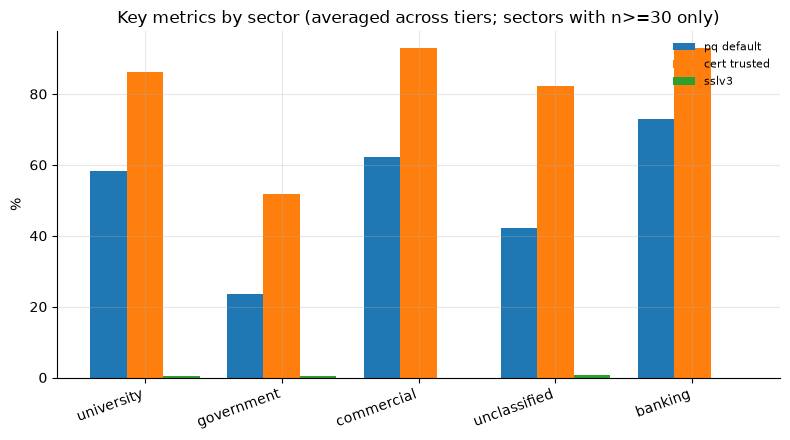

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_cols = [c for c in ["pq_default", "cert_trusted", "sslv3"] if c in METRIC_DEFS]
cat_totals = summary.groupby("category")["domains"].sum().sort_values(ascending=False)
top_cat = cat_totals[cat_totals >= MIN_N].head(6).index
excluded = cat_totals[cat_totals < MIN_N]
if len(excluded):
    print(f"Excluded from this chart (fewer than {MIN_N} domains total): "
          + ", ".join(f"{c} (n={n})" for c, n in excluded.items()))

plot_df = summary[summary["category"].isin(top_cat)]
x = np.arange(len(top_cat))
w = 0.8 / max(len(plot_cols), 1)
for i, col in enumerate(plot_cols):
    vals = [plot_df.loc[plot_df["category"] == c, f"{col}_pct"].mean() for c in top_cat]
    ax.bar(x + i * w, vals, w, label=col.replace("_", " "))
ax.set_xticks(x + w * (len(plot_cols) - 1) / 2)
ax.set_xticklabels(top_cat, rotation=20, ha="right")
ax.set_ylabel("%")
ax.set_title(f"Key metrics by sector (averaged across tiers; sectors with n>={MIN_N} only)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "d_sector_overview")
plt.show()

## 8. Export the joined table

Saved for direct reuse in the paper's analysis or by any later script, without re-joining
everything by hand each time. Includes every `_n`/`_den`/`_pct` column computed above, not just
the display-formatted versions.

In [37]:
out_path = PROC / "phase_d_joined.csv"
df.to_csv(out_path, index=False)
print(f"Wrote {out_path} ({len(df):,} rows, {df.shape[1]} columns)")

summary_path = Path("results/tables/phase_d_sector_tier_summary.csv")
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(summary_path, index=False)
print(f"Wrote {summary_path} ({len(summary)} rows) -- the full-precision version of Section 7's table")

Wrote data/measurement/processed/phase_d_joined.csv (7,999 rows, 71 columns)
Wrote results/tables/phase_d_sector_tier_summary.csv (11 rows) -- the full-precision version of Section 7's table
